# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhammad Zaki Nanda Wahyudi | 5054251007 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [30]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

# Import library yang dibutuhkan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Set random seed agar hasil eksperimen dapat direproduksi
torch.manual_seed(42)
np.random.seed(42)

In [4]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

# Load dataset dan tampilkan beberapa baris pertama
df = pd.read_csv("Churn_Modelling.csv")
display(df.head())

# Jumlah baris dan kolom
print("Jumlah baris dan kolom:", df.shape)

# Tipe data
print("\nInformasi dataset:")
df.info()

# Statistik deskriptif
print("\nStatistik deskriptif:")
display(df.describe())

# Jumlah missing value
print("\nJumlah missing value per kolom:")
print(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Jumlah baris dan kolom: (10000, 14)

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Statistik deskriptif:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Jumlah missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Jumlah per kelas:
Exited
0    7963
1    2037
Name: count, dtype: int64

Persentase per kelas (%):
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


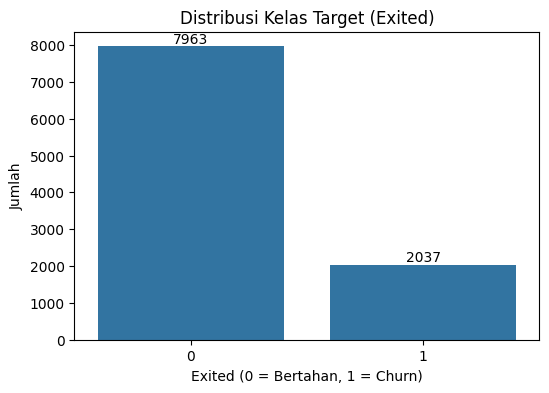

In [5]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

# Distribusi kelas target (Exited)
class_counts = df["Exited"].value_counts()
class_pct = df["Exited"].value_counts(normalize=True) * 100

print("Jumlah per kelas:")
print(class_counts)
print("\nPersentase per kelas (%):")
print(class_pct.round(2))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Exited", data=df)
plt.title("Distribusi Kelas Target (Exited)")
plt.xlabel("Exited (0 = Bertahan, 1 = Churn)")
plt.ylabel("Jumlah")

# Tampilkan jumlah di atas bar
for container in ax.containers:
    ax.bar_label(container)

plt.show()

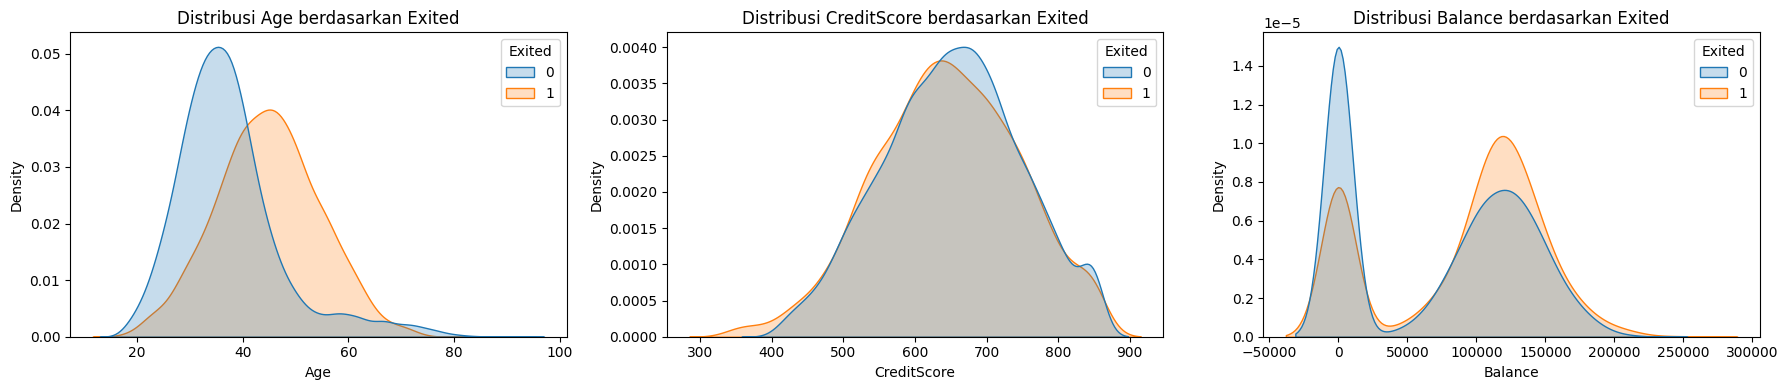

In [6]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

# Distribusi fitur numerik berdasarkan kelas Exited
num_features = ["Age", "CreditScore", "Balance"]

fig, axes = plt.subplots(1, len(num_features), figsize=(18, 4))

for ax, col in zip(axes, num_features):
    sns.kdeplot(data=df, x=col, hue="Exited", fill=True, common_norm=False, ax=ax)
    ax.set_title(f"Distribusi {col} berdasarkan Exited")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

Proporsi churn (%) berdasarkan Geography:
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64

Proporsi churn (%) berdasarkan Gender:
Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64

Proporsi churn (%) berdasarkan IsActiveMember:
IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64

Proporsi churn (%) berdasarkan NumOfProducts:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64



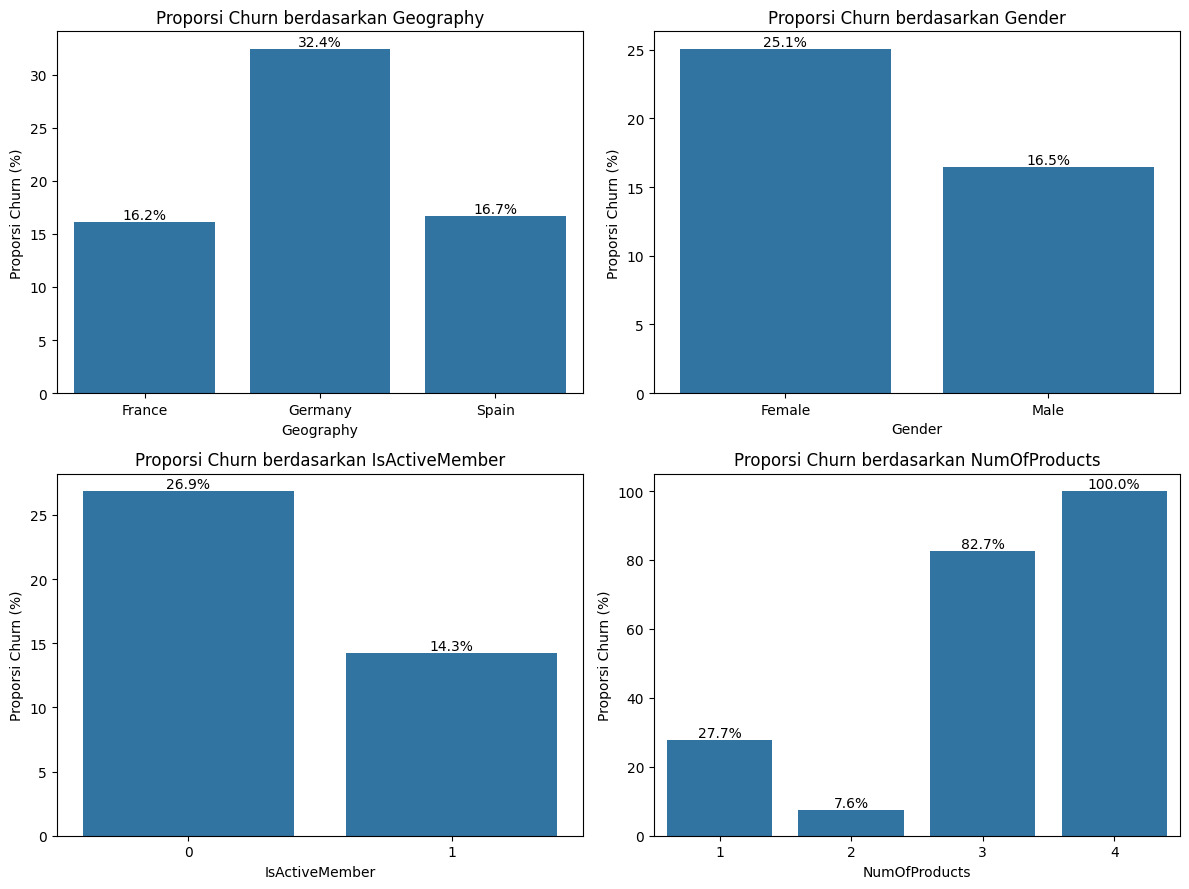

In [7]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

# Proporsi churn untuk setiap kategori pada fitur kategorikal
cat_features = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, col in zip(axes, cat_features):
    churn_rate = df.groupby(col)["Exited"].mean() * 100
    print(f"Proporsi churn (%) berdasarkan {col}:")
    print(churn_rate.round(2))
    print()

    sns.barplot(x=churn_rate.index, y=churn_rate.values, ax=ax)
    ax.set_title(f"Proporsi Churn berdasarkan {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Proporsi Churn (%)")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

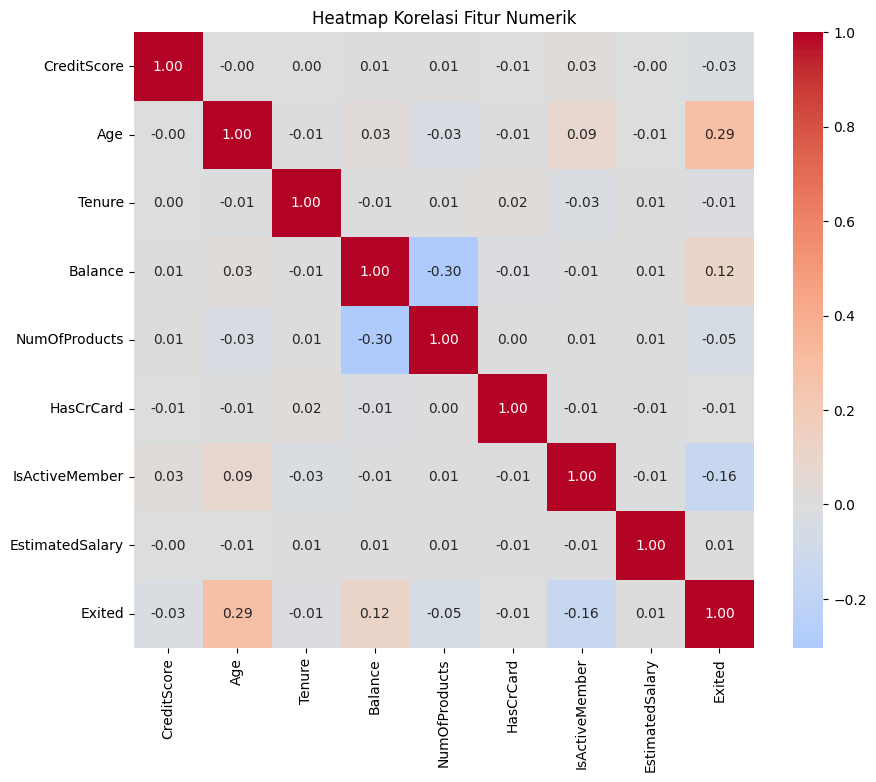

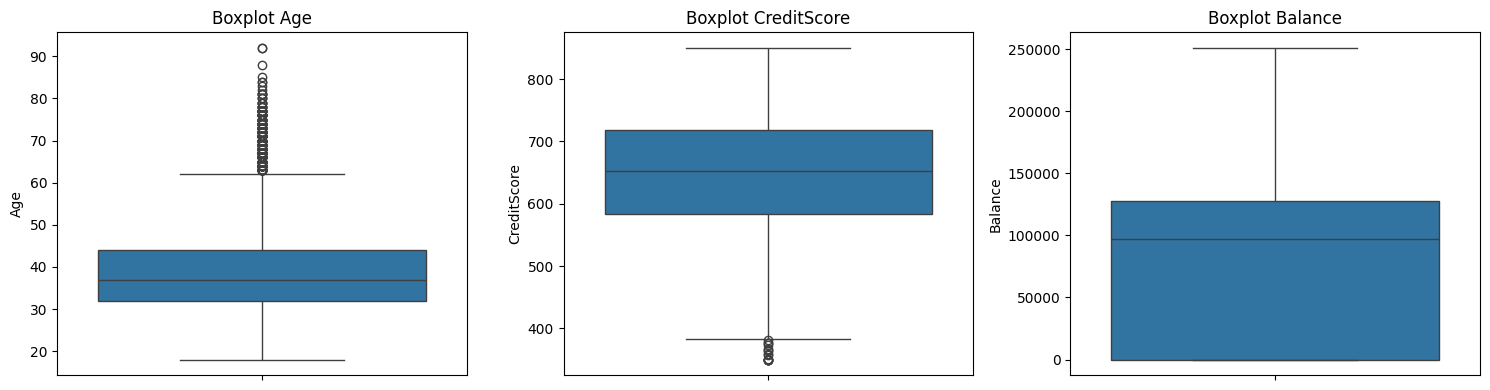

Jumlah baris duplikat: 0

Jumlah unique value per kolom:
RowNumber          10000
CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64


In [8]:
# 1. Korelasi antar fitur numerik (heatmap)
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop(["RowNumber", "CustomerId"])

plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap Korelasi Fitur Numerik")
plt.show()

# 2. Outlier (boxplot)
outlier_features = ["Age", "CreditScore", "Balance"]

fig, axes = plt.subplots(1, len(outlier_features), figsize=(15, 4))

for ax, col in zip(axes, outlier_features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot {col}")

plt.tight_layout()
plt.show()

# 3. Cek duplikat dan unique value tiap kolom
print("Jumlah baris duplikat:", df.duplicated().sum())

print("\nJumlah unique value per kolom:")
print(df.nunique())

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [9]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# Drop kolom yang tidak relevan untuk prediksi
# - RowNumber  : hanya nomor urut baris, tidak membawa informasi tentang nasabah
# - CustomerId : ID unik tiap nasabah, tidak punya pola yang bisa dipelajari model
# - Surname    : nama belakang nasabah, tidak relevan untuk memprediksi churn
#                dan berpotensi menambah noise/dimensi yang tidak perlu setelah encoding
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

print("Shape setelah drop:", df.shape)
df.head()

Shape setelah drop: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

# Pisahkan fitur (X) dan target (y)
X = df.drop(columns=["Exited"])
y = df["Exited"]

# Bagi data: 70% train, 30% sisanya (temp) untuk validation dan test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Bagi temp menjadi 15% validation dan 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Cek ukuran dan distribusi kelas di setiap set
print("Ukuran train :", X_train.shape)
print("Ukuran val   :", X_val.shape)
print("Ukuran test  :", X_test.shape)

print("\nProporsi kelas Exited (%):")
print("Train:", (y_train.value_counts(normalize=True) * 100).round(2).to_dict())
print("Val  :", (y_val.value_counts(normalize=True) * 100).round(2).to_dict())
print("Test :", (y_test.value_counts(normalize=True) * 100).round(2).to_dict())

Ukuran train : (7000, 10)
Ukuran val   : (1500, 10)
Ukuran test  : (1500, 10)

Proporsi kelas Exited (%):
Train: {0: 79.63, 1: 20.37}
Val  : {0: 79.6, 1: 20.4}
Test : {0: 79.67, 1: 20.33}


In [12]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

# Tentukan kolom berdasarkan jenisnya
cat_cols = ["Geography", "Gender"]
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
bin_cols = ["HasCrCard", "IsActiveMember"]  # sudah biner (0/1), diteruskan apa adanya

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
        ("bin", "passthrough", bin_cols),
    ],
    sparse_threshold=0,  # output berupa array dense
)

# Fit hanya pada train set, lalu transform ke train, validation, dan test
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

# Cek hasil
feature_names = preprocessor.get_feature_names_out()
print("Shape train:", X_train_proc.shape)
print("Shape val  :", X_val_proc.shape)
print("Shape test :", X_test_proc.shape)
print("\nNama fitur setelah transformasi:")
print(list(feature_names))

Shape train: (7000, 12)
Shape val  : (1500, 12)
Shape test : (1500, 12)

Nama fitur setelah transformasi:
['cat__Geography_France', 'cat__Geography_Germany', 'cat__Geography_Spain', 'cat__Gender_Male', 'num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__EstimatedSalary', 'bin__HasCrCard', 'bin__IsActiveMember']


In [13]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

# Ubah X dan y menjadi tensor float32
X_train_t = torch.tensor(X_train_proc, dtype=torch.float32)
X_val_t = torch.tensor(X_val_proc, dtype=torch.float32)
X_test_t = torch.tensor(X_test_proc, dtype=torch.float32)

# y diubah menjadi bentuk (N, 1)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# DataLoader untuk train set (shuffle=True)
batch_size = 32
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Cek bentuk tensor
print("X_train:", X_train_t.shape, "| y_train:", y_train_t.shape)
print("X_val  :", X_val_t.shape, "| y_val  :", y_val_t.shape)
print("X_test :", X_test_t.shape, "| y_test :", y_test_t.shape)

X_train: torch.Size([7000, 12]) | y_train: torch.Size([7000, 1])
X_val  : torch.Size([1500, 12]) | y_val  : torch.Size([1500, 1])
X_test : torch.Size([1500, 12]) | y_test : torch.Size([1500, 1])


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [16]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

# Inisialisasi dan latih model Logistic Regression menggunakan train set
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_proc, y_train)

# Prediksi pada test set: label dan probabilitas kelas 1
y_pred_lr = log_reg.predict(X_test_proc)
y_prob_lr = log_reg.predict_proba(X_test_proc)[:, 1]

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [19]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super(ANN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),  # 1 hidden layer
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)           # 1 neuron output (logit, tanpa Sigmoid)
        )

    def forward(self, x):
        return self.network(x)

# Inisialisasi model
input_dim = X_train_t.shape[1]
model = ANN(input_dim)

# Tampilkan arsitektur model
print(model)

# Hitung jumlah parameter
total_params = sum(p.numel() for p in model.parameters())
print("\nJumlah parameter:", total_params)

ANN(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)

Jumlah parameter: 225


In [20]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

# Hyperparameter
learning_rate = 0.001
num_epochs = 50
batch_size = 32  # sama dengan batch_size pada train_loader

# Loss function
criterion = nn.BCEWithLogitsLoss()


def evaluate(model, X, y, criterion):
    """Hitung loss dan accuracy pada satu set data."""
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        preds = (torch.sigmoid(logits) >= 0.5).float()
        acc = (preds == y).float().mean().item()
    return loss, acc


def train_model(model, train_loader, X_train, y_train, X_val, y_val,
                criterion, optimizer, num_epochs):
    """Training loop yang dapat digunakan ulang. Mengembalikan history."""
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(num_epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            outputs = model(X_batch)               # forward
            loss = criterion(outputs, y_batch)     # hitung loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Akhir epoch: hitung loss dan accuracy pada train set dan validation set
        train_loss, train_acc = evaluate(model, X_train, y_train, criterion)
        val_loss, val_acc = evaluate(model, X_val, y_val, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    return history


# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Jalankan training
history = train_model(model, train_loader, X_train_t, y_train_t, X_val_t, y_val_t,
                      criterion, optimizer, num_epochs)

Epoch [1/50] Train Loss: 0.4496, Train Acc: 0.7969 | Val Loss: 0.4412, Val Acc: 0.7960
Epoch [2/50] Train Loss: 0.4317, Train Acc: 0.8074 | Val Loss: 0.4189, Val Acc: 0.8107
Epoch [3/50] Train Loss: 0.4207, Train Acc: 0.8147 | Val Loss: 0.4067, Val Acc: 0.8173
Epoch [4/50] Train Loss: 0.4088, Train Acc: 0.8207 | Val Loss: 0.3937, Val Acc: 0.8200
Epoch [5/50] Train Loss: 0.3962, Train Acc: 0.8321 | Val Loss: 0.3806, Val Acc: 0.8267
Epoch [6/50] Train Loss: 0.3855, Train Acc: 0.8394 | Val Loss: 0.3702, Val Acc: 0.8360
Epoch [7/50] Train Loss: 0.3769, Train Acc: 0.8437 | Val Loss: 0.3631, Val Acc: 0.8440
Epoch [8/50] Train Loss: 0.3704, Train Acc: 0.8467 | Val Loss: 0.3567, Val Acc: 0.8460
Epoch [9/50] Train Loss: 0.3654, Train Acc: 0.8490 | Val Loss: 0.3524, Val Acc: 0.8493
Epoch [10/50] Train Loss: 0.3615, Train Acc: 0.8496 | Val Loss: 0.3473, Val Acc: 0.8520
Epoch [11/50] Train Loss: 0.3591, Train Acc: 0.8500 | Val Loss: 0.3457, Val Acc: 0.8533
Epoch [12/50] Train Loss: 0.3563, Train A

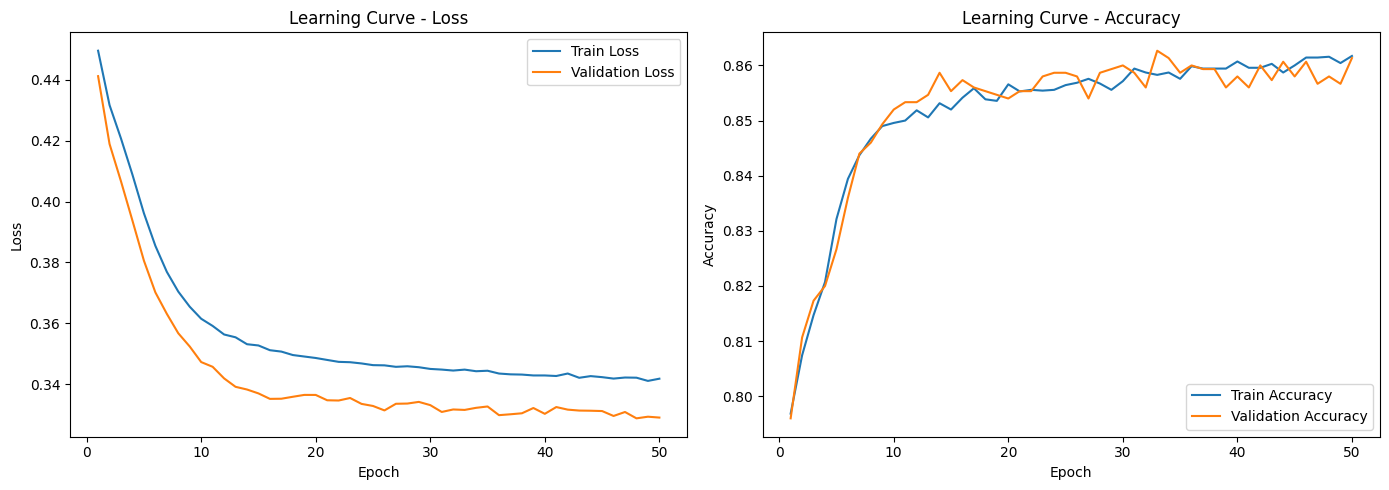

In [21]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

# Learning curve: loss dan accuracy (train vs validation)
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot loss
axes[0].plot(epochs, history["train_loss"], label="Train Loss")
axes[0].plot(epochs, history["val_loss"], label="Validation Loss")
axes[0].set_title("Learning Curve - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Plot accuracy
axes[1].plot(epochs, history["train_acc"], label="Train Accuracy")
axes[1].plot(epochs, history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Learning Curve - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [22]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

# Prediksi pada test set
model.eval()
with torch.no_grad():
    logits_test = model(X_test_t)
    y_prob_ann = torch.sigmoid(logits_test)          # logit -> probabilitas
    y_pred_ann = (y_prob_ann >= 0.5).float()         # probabilitas -> label (threshold 0.5)

# Simpan dalam bentuk numpy array
y_prob_ann = y_prob_ann.numpy().flatten()
y_pred_ann = y_pred_ann.numpy().flatten().astype(int)

## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [23]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, input_dim, hidden_dims=(32, 16, 8), dropout_p=0.3):
        super(DeepANN, self).__init__()
        layers = []
        in_dim = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(in_dim, h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_p))  # Dropout di antara hidden layer
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))       # 1 neuron output (logit, tanpa Sigmoid)
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# Inisialisasi model
input_dim = X_train_t.shape[1]
model_deep = DeepANN(input_dim)

# Tampilkan arsitektur model
print(model_deep)

# Hitung jumlah parameter
total_params_deep = sum(p.numel() for p in model_deep.parameters())
print("\nJumlah parameter:", total_params_deep)

DeepANN(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=16, out_features=8, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=8, out_features=1, bias=True)
  )
)

Jumlah parameter: 1089


Epoch [1/50] Train Loss: 0.4547, Train Acc: 0.7963 | Val Loss: 0.4509, Val Acc: 0.7960
Epoch [2/50] Train Loss: 0.4223, Train Acc: 0.7980 | Val Loss: 0.4119, Val Acc: 0.7980
Epoch [3/50] Train Loss: 0.4059, Train Acc: 0.8331 | Val Loss: 0.3958, Val Acc: 0.8273
Epoch [4/50] Train Loss: 0.3781, Train Acc: 0.8451 | Val Loss: 0.3655, Val Acc: 0.8447
Epoch [5/50] Train Loss: 0.3645, Train Acc: 0.8513 | Val Loss: 0.3538, Val Acc: 0.8493
Epoch [6/50] Train Loss: 0.3611, Train Acc: 0.8484 | Val Loss: 0.3478, Val Acc: 0.8500
Epoch [7/50] Train Loss: 0.3569, Train Acc: 0.8516 | Val Loss: 0.3444, Val Acc: 0.8560
Epoch [8/50] Train Loss: 0.3546, Train Acc: 0.8520 | Val Loss: 0.3415, Val Acc: 0.8467
Epoch [9/50] Train Loss: 0.3519, Train Acc: 0.8550 | Val Loss: 0.3402, Val Acc: 0.8553
Epoch [10/50] Train Loss: 0.3508, Train Acc: 0.8544 | Val Loss: 0.3419, Val Acc: 0.8480
Epoch [11/50] Train Loss: 0.3493, Train Acc: 0.8561 | Val Loss: 0.3372, Val Acc: 0.8587
Epoch [12/50] Train Loss: 0.3466, Train A

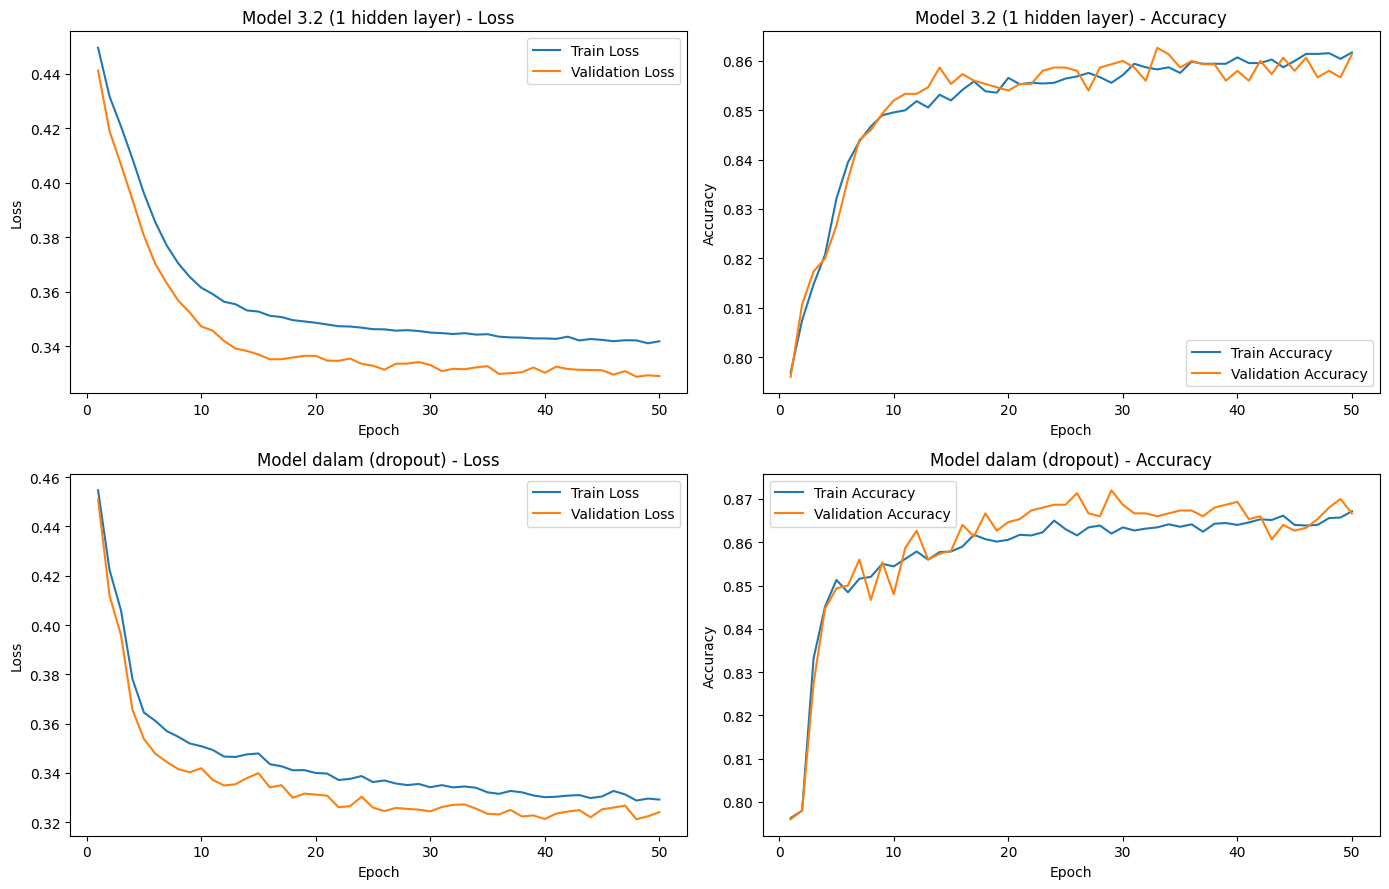

Model 3.2 (1 hidden layer): selisih loss (val - train) = -0.0128, selisih accuracy (train - val) = 0.0004
Model dalam (dropout): selisih loss (val - train) = -0.0051, selisih accuracy (train - val) = 0.0005


In [24]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

# Latih model dalam (sama seperti 3.2: loss, optimizer, learning rate, epoch, dan batch size yang sama)
criterion = nn.BCEWithLogitsLoss()
optimizer_deep = torch.optim.Adam(model_deep.parameters(), lr=learning_rate)

history_deep = train_model(model_deep, train_loader, X_train_t, y_train_t, X_val_t, y_val_t,
                           criterion, optimizer_deep, num_epochs)

# Learning curve: baris atas = model 3.2, baris bawah = model dalam (dropout)
histories = [("Model 3.2 (1 hidden layer)", history),
             ("Model dalam (dropout)", history_deep)]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for row, (name, h) in enumerate(histories):
    epochs = range(1, len(h["train_loss"]) + 1)

    axes[row, 0].plot(epochs, h["train_loss"], label="Train Loss")
    axes[row, 0].plot(epochs, h["val_loss"], label="Validation Loss")
    axes[row, 0].set_title(f"{name} - Loss")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Loss")
    axes[row, 0].legend()

    axes[row, 1].plot(epochs, h["train_acc"], label="Train Accuracy")
    axes[row, 1].plot(epochs, h["val_acc"], label="Validation Accuracy")
    axes[row, 1].set_title(f"{name} - Accuracy")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("Accuracy")
    axes[row, 1].legend()

plt.tight_layout()
plt.show()

# Selisih train vs validation di epoch terakhir (membantu menilai overfitting)
for name, h in histories:
    gap_loss = h["val_loss"][-1] - h["train_loss"][-1]
    gap_acc = h["train_acc"][-1] - h["val_acc"][-1]
    print(f"{name}: selisih loss (val - train) = {gap_loss:.4f}, "
          f"selisih accuracy (train - val) = {gap_acc:.4f}")

In [25]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

# Prediksi pada test set menggunakan model dalam (dropout)
model_deep.eval()
with torch.no_grad():
    logits_test_deep = model_deep(X_test_t)
    y_prob_deep = torch.sigmoid(logits_test_deep)    # logit -> probabilitas kelas 1
    y_pred_deep = (y_prob_deep >= 0.5).float()       # probabilitas -> label (threshold 0.5)

# Simpan dalam bentuk numpy array
y_prob_deep = y_prob_deep.numpy().flatten()
y_pred_deep = y_pred_deep.numpy().flatten().astype(int)

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [26]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Pilih arsitektur terbaik dari 3.2 atau 3.3
best_arch = "deep"

# Buat ulang model agar bobot mulai dari awal
torch.manual_seed(42)
model_weighted = DeepANN(input_dim)

# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
pos_weight = n_neg / n_pos
print("pos_weight:", round(float(pos_weight), 4))

# Loss function dengan class weight
criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))

# Optimizer dan training (hyperparameter sama seperti sebelumnya)
optimizer_weighted = torch.optim.Adam(model_weighted.parameters(), lr=learning_rate)

history_weighted = train_model(model_weighted, train_loader, X_train_t, y_train_t, X_val_t, y_val_t,
                               criterion_weighted, optimizer_weighted, num_epochs)

pos_weight: 3.9088
Epoch [1/50] Train Loss: 1.0181, Train Acc: 0.6530 | Val Loss: 1.0011, Val Acc: 0.6627
Epoch [2/50] Train Loss: 0.8821, Train Acc: 0.7861 | Val Loss: 0.8543, Val Acc: 0.8007
Epoch [3/50] Train Loss: 0.8133, Train Acc: 0.7571 | Val Loss: 0.7829, Val Acc: 0.7687
Epoch [4/50] Train Loss: 0.7926, Train Acc: 0.7513 | Val Loss: 0.7583, Val Acc: 0.7500
Epoch [5/50] Train Loss: 0.7902, Train Acc: 0.7727 | Val Loss: 0.7640, Val Acc: 0.7747
Epoch [6/50] Train Loss: 0.7800, Train Acc: 0.7724 | Val Loss: 0.7540, Val Acc: 0.7667
Epoch [7/50] Train Loss: 0.7792, Train Acc: 0.7796 | Val Loss: 0.7491, Val Acc: 0.7787
Epoch [8/50] Train Loss: 0.7755, Train Acc: 0.7854 | Val Loss: 0.7462, Val Acc: 0.7867
Epoch [9/50] Train Loss: 0.7683, Train Acc: 0.7694 | Val Loss: 0.7419, Val Acc: 0.7693
Epoch [10/50] Train Loss: 0.7653, Train Acc: 0.7920 | Val Loss: 0.7365, Val Acc: 0.7967
Epoch [11/50] Train Loss: 0.7624, Train Acc: 0.7881 | Val Loss: 0.7332, Val Acc: 0.7887
Epoch [12/50] Train Lo

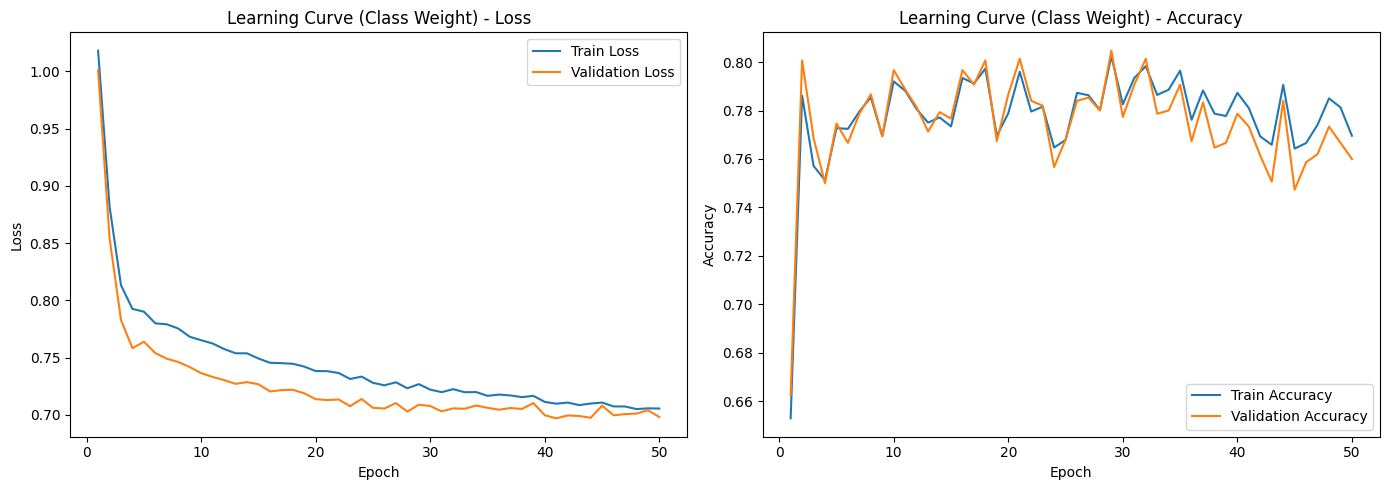

In [27]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

# Learning curve: loss dan accuracy (train vs validation) model dengan class weight
epochs = range(1, len(history_weighted["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history_weighted["train_loss"], label="Train Loss")
axes[0].plot(epochs, history_weighted["val_loss"], label="Validation Loss")
axes[0].set_title("Learning Curve (Class Weight) - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs, history_weighted["train_acc"], label="Train Accuracy")
axes[1].plot(epochs, history_weighted["val_acc"], label="Validation Accuracy")
axes[1].set_title("Learning Curve (Class Weight) - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

# Prediksi pada test set
model_weighted.eval()
with torch.no_grad():
    logits_test_w = model_weighted(X_test_t)
    y_prob_weighted = torch.sigmoid(logits_test_w)    # logit -> probabilitas kelas 1
    y_pred_weighted = (y_prob_weighted >= 0.5).float()  # probabilitas -> label (threshold 0.5)

# Simpan dalam bentuk numpy array
y_prob_weighted = y_prob_weighted.numpy().flatten()
y_pred_weighted = y_pred_weighted.numpy().flatten().astype(int)

# 4. Evaluasi Model

In [28]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

# Tabel perbandingan metrik evaluasi pada test set
predictions = {
    "Logistic Regression": y_pred_lr,
    "ANN 1 Hidden Layer": y_pred_ann,
    "ANN Dalam (Dropout)": y_pred_deep,
    "ANN Dalam + Class Weight": y_pred_weighted,
}

results = []
for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
    })

df_results = pd.DataFrame(results).set_index("Model").round(4)
display(df_results)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092
ANN 1 Hidden Layer,0.8627,0.7929,0.4393,0.5654
ANN Dalam (Dropout),0.8647,0.7931,0.4525,0.5762
ANN Dalam + Class Weight,0.7587,0.4483,0.8098,0.5771


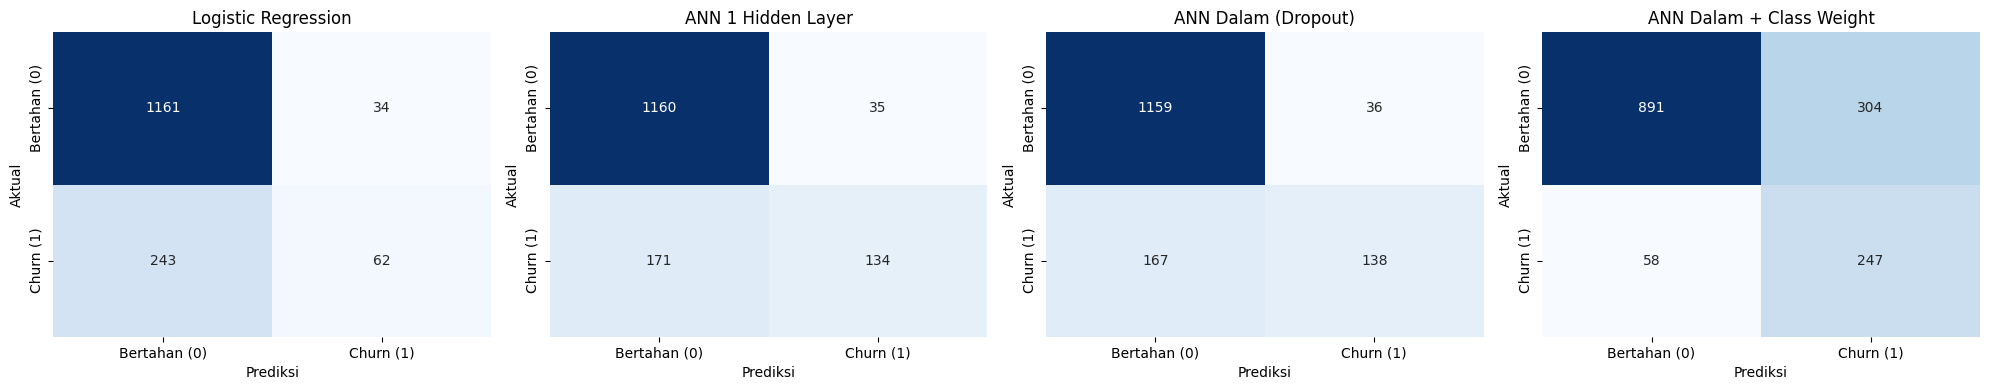

In [29]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

# Confusion matrix setiap model dalam satu baris subplot
fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Bertahan (0)", "Churn (1)"],
                yticklabels=["Bertahan (0)", "Churn (1)"])
    ax.set_title(name)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.tight_layout()
plt.show()

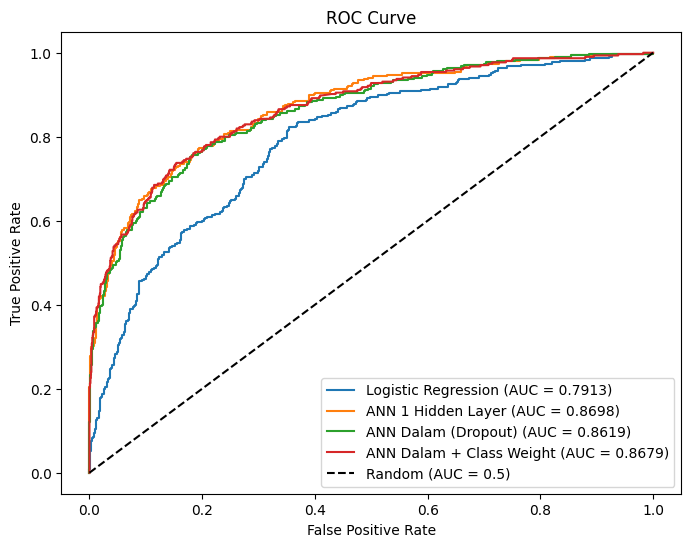

In [31]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

# Probabilitas kelas 1 dari setiap model
probabilities = {
    "Logistic Regression": y_prob_lr,
    "ANN 1 Hidden Layer": y_prob_ann,
    "ANN Dalam (Dropout)": y_prob_deep,
    "ANN Dalam + Class Weight": y_prob_weighted,
}

# ROC Curve seluruh model dalam satu plot
plt.figure(figsize=(8, 6))

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.


---

## Analisis

### 1. Gambaran data dan konteks evaluasi
Dataset berisi 10.000 nasabah dengan 20,37% churn (2.037 churn vs 7.963 bertahan), sehingga data tergolong imbalanced. Pembagian stratified menjaga proporsi ini di semua set (test set: 1.500 sampel, 305 churn dan 1.195 bertahan). Akibatnya, **accuracy kurang bisa diandalkan**. Model yang selalu menebak "bertahan" saja sudah mendapat accuracy sekitar 0,80. Karena itu, perbandingan model lebih tepat memakai precision, recall, F1 kelas churn, dan AUC.

### 2. Perbandingan Logistic Regression dan konfigurasi ANN

| Model | Acc | Precision | Recall | F1 | AUC | TP | FN | FP |
|---|---|---|---|---|---|---|---|---|
| Logistic Regression | 0,8153 | 0,6458 | 0,2033 | 0,3092 | 0,7913 | 62 | 243 | 34 |
| ANN 1 Hidden Layer | 0,8627 | 0,7929 | 0,4393 | 0,5654 | 0,8698 | 134 | 171 | 35 |
| ANN Dalam (Dropout) | 0,8647 | 0,7931 | 0,4525 | 0,5762 | 0,8619 | 138 | 167 | 36 |
| ANN Dalam + Class Weight | 0,7587 | 0,4483 | 0,8098 | 0,5771 | 0,8679 | 247 | 58 | 304 |

**Logistic Regression (baseline)** adalah yang terlemah. Model ini hanya menemukan 62 dari 305 nasabah churn (recall 0,20), dan 243 nasabah churn lolos. Accuracy 0,8153 terlihat lumayan, tetapi hanya karena kelas mayoritas mudah ditebak. F1 hanya 0,31 dan AUC 0,7913 juga yang terendah. Hubungan antara fitur dan churn kemungkinan tidak linear (misalnya efek `Age`, `NumOfProducts`, dan `Balance`), sehingga model linear tidak cukup menangkapnya.

**ANN tanpa class weight** jauh lebih baik. Dengan false positive yang hampir sama (34 vs 35), ANN 1 hidden layer menemukan 134 nasabah churn, lebih dari dua kali lipat baseline. Recall naik dari 0,20 ke 0,44, F1 dari 0,31 ke 0,57, dan AUC dari 0,79 ke 0,87. Jadi ANN memang layak dipakai dibanding baseline. Meski begitu, recall di bawah 0,5 berarti lebih dari separuh nasabah churn masih tidak terdeteksi.

### 3. Bentuk learning curve

**ANN 1 hidden layer (3.2).** Train loss turun dari sekitar 0,45 ke 0,34 dan validation loss dari 0,44 ke 0,33, lalu keduanya mendatar setelah sekitar epoch 20. Di epoch 50, selisih loss (val − train) = −0,0128 dan selisih accuracy (train − val) = 0,0004. Validation loss tidak pernah naik, sehingga **tidak ada overfitting**.

**ANN dalam dengan dropout (3.3).** Turun lebih cepat di awal (train loss sekitar 0,36 di epoch 5, vs 0,40 pada model 3.2), lalu mendatar di sekitar 0,33 (train) dan 0,324 (val). Selisih loss = −0,0051 dan selisih accuracy = 0,0005. Juga **tidak ada overfitting**.

Validation loss yang sedikit di bawah train loss pada kedua model kemungkinan besar karena variasi sampel validation set (hanya 1.500 data), bukan tanda masalah. Karena kurva sudah mendatar dengan accuracy sekitar 0,86–0,87 dan tanpa gap, model cenderung sudah mencapai batas kemampuan dengan fitur dan arsitektur ini. Ada kemungkinan sedikit underfitting, tetapi ini hanya dugaan dari pola kurva.

**ANN + class weight (3.4).** Loss berada di skala lain (sekitar 1,0 turun ke sekitar 0,70) karena kesalahan pada kelas churn dihitung 3,9088 kali lebih berat (`pos_weight`), sehingga nilainya tidak bisa dibandingkan langsung dengan model lain. Kurvanya tetap turun mulus dan mendatar, dengan gap train–val kecil (loss akhir 0,7056 vs 0,6981), jadi tetap tidak overfitting. Accuracy-nya berfluktuasi tajam antar epoch (sekitar 0,75–0,80), sementara loss-nya mulus. Dengan pembobotan, sebagian besar sampel berada dekat batas keputusan pada threshold 0,5, sehingga perubahan kecil pada bobot menggeser banyak prediksi sekaligus.

### 4. Pengaruh penambahan layer dan Dropout
Model dalam memiliki 1.089 parameter, sekitar 4,8 kali lipat model 3.2 (225 parameter). Peningkatannya sangat kecil: F1 naik 0,5654 → 0,5762, recall 0,4393 → 0,4525, accuracy 0,8627 → 0,8647. Dalam hitungan kasus, itu hanya 4 nasabah churn tambahan yang terdeteksi (134 → 138) dengan 1 false positive tambahan. AUC malah sedikit turun (0,8698 → 0,8619). Jadi penambahan layer dan dropout **tidak memberi perbaikan yang berarti**.

Penyebabnya masuk akal: karena model 3.2 sudah tidak overfitting, dropout (yang tujuannya mengurangi overfitting) tidak punya banyak hal untuk diperbaiki. Manfaat yang terlihat hanya konvergensi yang lebih cepat. Perlu dicatat juga bahwa semua hasil berasal dari satu kali training dengan satu seed, sehingga selisih sekecil ini belum cukup untuk menyimpulkan satu model benar-benar lebih baik.

### 5. Pengaruh class weight terhadap precision dan recall churn
Class weight menggeser keseimbangan antara precision dan recall secara drastis (dibandingkan ANN dalam tanpa class weight, arsitektur yang sama):
- **Recall** naik dari 0,4525 ke 0,8098. Nasabah churn yang terlewat (FN) turun dari 167 ke 58.
- **Precision** turun dari 0,7931 ke 0,4483. Nasabah yang bertahan tetapi salah ditandai churn (FP) naik dari 36 ke 304.
- **Accuracy** turun dari 0,8647 ke 0,7587, karena banyak nasabah mayoritas ikut salah diklasifikasikan.
- Model sekarang memprediksi 551 nasabah sebagai churn, padahal yang sebenarnya churn hanya 305.

**F1 praktis tidak berubah** (0,5762 vs 0,5771), karena kenaikan recall hampir persis diimbangi turunnya precision. **AUC juga hampir sama** (0,8619 vs 0,8679). Artinya, class weight tidak membuat model lebih pandai membedakan churn dari non-churn. Yang berubah hanyalah titik operasinya: model menjadi lebih agresif menandai churn pada threshold 0,5. Jadi class weight berguna sebagai pengatur trade-off, bukan peningkat kualitas model.

### 6. Ringkasan
1. ANN jelas mengungguli Logistic Regression baseline (F1 sekitar 0,57 vs 0,31; AUC sekitar 0,86–0,87 vs 0,79).
2. Tidak ada overfitting pada ketiga model. Kurva train dan validation berdekatan dan mendatar.
3. Penambahan layer dan dropout hanya memberi perbaikan marginal, karena model sederhana sudah tidak overfitting.
4. Class weight meningkatkan recall churn secara besar (0,45 → 0,81) dengan mengorbankan precision (0,79 → 0,45), tanpa perubahan berarti pada F1 maupun AUC.
5. Pemilihan model akhir bergantung pada biaya kesalahan. Jika kehilangan nasabah churn jauh lebih mahal dibanding biaya kampanye retensi yang salah sasaran, model dengan class weight lebih sesuai. Jika diinginkan prediksi yang lebih bersih, ANN dalam (dropout) lebih sesuai.

---

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**

1. Semua model ANN mengungguli Logistic Regression sebagai baseline. Logistic Regression hanya mencapai F1 0,3092 dan recall 0,2033, sedangkan ANN mencapai F1 sekitar 0,57 dan AUC sekitar 0,86-0,87 (baseline: 0,7913). Ini menunjukkan hubungan antara fitur dan churn bersifat non-linear sehingga ANN lebih sesuai.

2. Tidak ada tanda overfitting pada ketiga konfigurasi ANN. Kurva train dan validation berdekatan dan mendatar, dengan selisih loss (val - train) sebesar -0,0128 untuk ANN 1 hidden layer dan -0,0051 untuk ANN dalam, serta selisih accuracy di bawah 0,001.

3. Penambahan layer dan Dropout hanya memberi peningkatan marginal. Parameter naik dari 225 menjadi 1.089, tetapi F1 hanya naik dari 0,5654 ke 0,5762 (4 nasabah churn tambahan terdeteksi) dan AUC sedikit turun dari 0,8698 ke 0,8619. Karena model sederhana sudah tidak overfitting, Dropout tidak punya banyak hal untuk diperbaiki. Manfaat yang terlihat hanya konvergensi yang lebih cepat.

4. Class weight (pos_weight = 3,9088) menggeser trade-off precision dan recall secara drastis. Recall churn naik dari 0,4525 ke 0,8098 (nasabah churn yang terlewat turun dari 167 ke 58), tetapi precision turun dari 0,7931 ke 0,4483 dan accuracy turun dari 0,8647 ke 0,7587. F1 (0,5771) dan AUC (0,8679) hampir tidak berubah, sehingga class weight hanya menggeser titik operasi model, bukan meningkatkan kemampuan model membedakan kelas.

5. Pemilihan model akhir bergantung pada biaya kesalahan. Jika kehilangan nasabah churn lebih mahal dibanding kampanye retensi yang salah sasaran, ANN dengan class weight lebih sesuai. Jika diinginkan prediksi yang lebih bersih, ANN dalam (Dropout) lebih sesuai.

6. Seluruh hasil berasal dari satu kali training dengan satu seed dan test set 1.500 sampel, sehingga selisih kecil antar model (misalnya F1 0,5654 vs 0,5762) belum cukup untuk menyimpulkan satu model benar-benar lebih baik.

**Saran**

1. Ulangi eksperimen dengan beberapa seed atau cross-validation, lalu laporkan rata-rata dan standar deviasi metrik agar perbandingan antar model lebih kuat.
2. Atur threshold keputusan berdasarkan validation set (misalnya lewat precision-recall curve) sebagai alternatif class weight, karena AUC menunjukkan kemampuan pemisahan kelas sudah setara dan yang berbeda hanya titik operasinya.
3. Coba teknik penanganan imbalance lain, seperti oversampling (SMOTE) atau undersampling, dan bandingkan dengan class weight.
4. Lakukan hyperparameter tuning (jumlah neuron, jumlah layer, learning rate, batch size, nilai Dropout, dan jumlah epoch), karena nilai-nilai tersebut dipilih tanpa pencarian sistematis.
5. Tambahkan early stopping berdasarkan validation loss agar jumlah epoch tidak perlu ditentukan manual.
6. Bandingkan dengan model berbasis pohon, seperti Random Forest atau Gradient Boosting, yang umumnya kuat pada data tabular dan dapat menjadi baseline tambahan.
7. Pertimbangkan feature engineering, misalnya rasio balance terhadap salary atau interaksi antara fitur yang berkaitan dengan churn (seperti `Age`, `NumOfProducts`, dan `IsActiveMember`), karena kurva yang sudah mendatar menunjukkan model mungkin sudah mencapai batas kemampuan dengan fitur yang ada.